# The Wisdom of Crowds: An Analysis of Prediction Markets 

## Introduction
The “wisdom of crowds” has long been considered an accurate predictor of outcomes, quantities, or optimal strategies. We consider crowdsourced information in the context of modern prediction markets. Since the 2024 presidential election, prediction markets have reached the mainstream media consciousness. 

Our dataset consists of **Polymarket** prediction market events and trades ranging through multiple categories (Sports, Politics, Crypto, Pop Culture). We are analyzing events and markets to consider the efficiency, accuracy, fairness, and predictability of such markets and their predictions.

Our current main questions and hypotheses are:
- Do prediction markets make accurate predictions (i.e., do probability prices reflect factual resolution chances)?
- Are a majority of market events with significant trading volume related to sports compared to politics?
- What percentage of market events are open to insider trading or abnormal volume anomalies?

## Any Changes
In our original proposal, we planned to use three sources of data: the Kaggle dataset for Polymarket, the Polymarket Data API, and the Kalshi Data API. Since then, our scope has changed to focus mainly on Polymarket. We've found that prediction markets incorporate more data then we can handle. Our initial ambitions of analyzing the entirety of both prediction market platform's historical event and market data had to be scaled back down to just a single prediction market given storage constraints. The market and event data proved to be >20GB of pure text data which we don't have the processing, storage or network infrastructure to cleanly analyze in a group of 4. We conduct our initial analysis over the Kaggle dataset as discussed while we set aside resources to process a predefined range of market and event data collected through API scraping. We've decided that we'll restrict our analysis to the past year of Polymarket events and markets and are considering further filtering of said data to obtain a manageable dataset

Currently, we are working with the readily available Kaggle Polymarket dataset. This initial dataset is substantial (43,840 events and 100,795 market-level records across 138 columns), providing us useful metadata like `lastTradePrice` and JSON `tags` to perform exploratory data analysis (EDA), and identify major cetegories to focus on for later. 

While we have built scrapers for Polymarket and collected some raw API data, we are saving broader ingestion for the future. Our strategy is to finalize our EDA on the Kaggle dataset to discover global trends, and then deploy our custom Polymarket API scrapers to pull targeted data for specific categories that we want to investigate deeper for our final submission.

## Data Cleaning
To ensure the data was usable, we performed several transformations. We:
1. Loaded the events and detailed markets data using pandas.
2. Filtered out unresolved/active markets to evaluate completed historical predictions where `closed == True`.
3. Coerced target indicators to numeric variables and constrained `lastTradePrice` (probability before resolution lock) to bounds `> 0.01` and `< 0.99` to ensure we filter out locked prices.
4. Parsed the resulting stringified JSON (e.g., `'["1", "0"]'`) representing resolutions into a definitive binary target variables (`1` and `0`) indicating whether the outcome turned out to be True or False.
5. Extracted proper primary categories (e.g., Sports, Politics) by processing the `tags` column, which was a JSON dictionary.

In [1]:
import pandas as pd
import numpy as np
import json
import plotly.express as px
import plotly.graph_objects as go
from sklearn.calibration import calibration_curve

# 1. Load data
df_markets = pd.read_csv('kaggle-dataset/polymarket_markets.csv')
df_events = pd.read_csv('kaggle-dataset/polymarket_events.csv')

# 2. Extract accurate values for 'Outcome' from JSON
resolved_markets = df_markets[df_markets['closed'] == True].copy()
resolved_markets['lastTradePrice'] = pd.to_numeric(resolved_markets['lastTradePrice'], errors='coerce')
    
# Filter out missing ones and limit ranges (prices lock at 1 or 0 after resolution)
resolved_markets = resolved_markets.dropna(subset=['lastTradePrice'])
resolved_markets = resolved_markets[(resolved_markets['lastTradePrice'] < 0.99) & (resolved_markets['lastTradePrice'] > 0.01)]

# 3. Parse outcomePrices. It's stored as a stringified list like '["1", "0"]'
def get_actual_outcome(op_str):
    try:
        op_list = json.loads(op_str)
        if op_list[0] == "1" or op_list[0] == 1:
            return 1
        elif op_list[0] == "0" or op_list[0] == 0:
            return 0
        else:
            return np.nan
    except:
        return np.nan

resolved_markets['actual_outcome'] = resolved_markets['outcomePrices'].apply(get_actual_outcome)
resolved_markets = resolved_markets.dropna(subset=['actual_outcome'])

display(resolved_markets[['id', 'question', 'lastTradePrice', 'actual_outcome']].head())

# 4. Extract Category data from JSON 'tags'
def extract_primary_tag(tag_str):
    try:
        if isinstance(tag_str, str):
            tags = json.loads(tag_str)
            if isinstance(tags, list) and len(tags) > 0:
                return tags[0].get('label', 'Unknown')
        return 'Unknown'
    except:
        return 'Unknown'

df_events['primary_category'] = df_events['tags'].apply(extract_primary_tag)
events_cleaned = df_events[df_events['primary_category'] != 'Unknown'].copy()

/var/folders/dh/gg9g2sr55mldcldx8ws6c6qw0000gn/T/ipykernel_39329/4059299199.py:9: DtypeWarning: Columns (0,5,9,16,26,28,29,32,36,39,40,42,44,47,63,64,65,69,70,85,93,94,95,96,99,103,108,111,114,137) have mixed types. Specify dtype option on import or set low_memory=False.
  df_markets = pd.read_csv('kaggle-dataset/polymarket_markets.csv')
/var/folders/dh/gg9g2sr55mldcldx8ws6c6qw0000gn/T/ipykernel_39329/4059299199.py:10: DtypeWarning: Columns (2,5,6,7,11,13,21,22,23,25,28,30,33,34,52,57,68) have mixed types. Specify dtype option on import or set low_memory=False.
  df_events = pd.read_csv('kaggle-dataset/polymarket_events.csv')


,id,question,lastTradePrice,actual_outcome
31,804102,Thunder vs. Warriors: 1H O/U 109.5,0.54,0.0
78,791299,Trail Blazers vs. Raptors: 1H Moneyline,0.16,0.0
468,802850,Spread: Timberwolves (-13.5),0.50,0.0
743,785908,Over $4M committed to the Makina public sale?,0.02,0.0
1494,803049,Blackhawks vs. Golden Knights: O/U 5.5,0.56,1.0


## Exploratory Data Analysis & Hypothesis Visualizations

### General Data Shapes
Our `df_events` dataframe contains events containing the sum totals of various specific probabilistic markets, measuring metadata like `active`, `volume`, `endDate`, and `description`.
Our `df_markets` dataframe contains the individual prediction markets, complete with questions posed, ending times, rules (stored as markdown), and `lastTradePrice` representing a probability market.

### Hypothesis 1: "For a majority of events, prediction markets make well-calibrated (accurate) predictions"

To test this, we examine **Resolved** markets and compare their **final probability** (what the market predicted right before it closed) to the **actual outcome** (whether it resolved to Yes or No).
We will visualize this through a Calibration Curve. If a market predicting "70% yes" actually resolves to "Yes" 70% of the time, the prediction markets are accurate.

**Why investigate this?** Because Prediction Markets treat beliefs as bets, their premise is that "Wisdom of Crowds" yields accurately calibrated predictions. If they fail to map proportionately to ground truth, their value diminishes drastically.

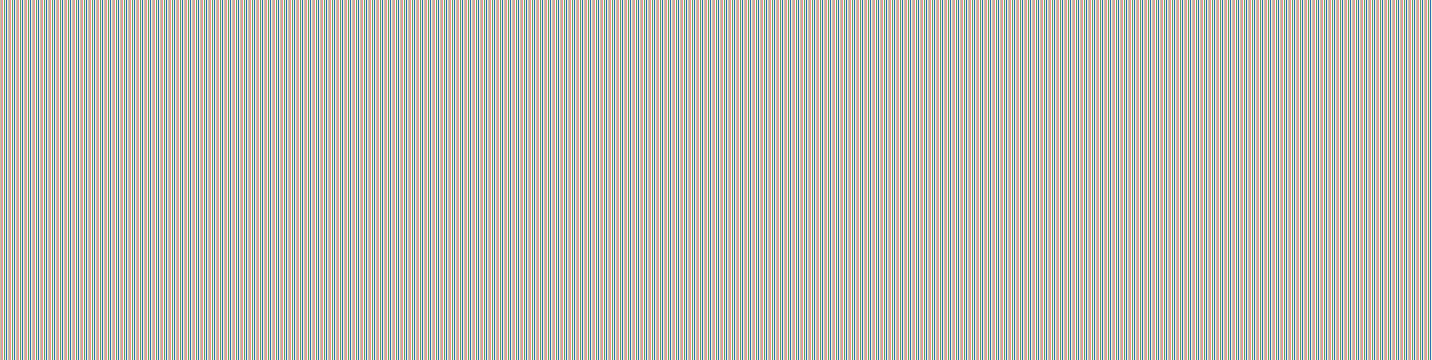

In [2]:
# Calibration Curve Data
# Bins the predicted probabilities into 10 buckets
prob_true, prob_pred = calibration_curve(resolved_markets['actual_outcome'], resolved_markets['lastTradePrice'], n_bins=10)

# Plotly Calibration Curve
fig_cal_curve = go.Figure()

fig_cal_curve.add_trace(go.Scatter(
    x=prob_pred, y=prob_true,
    mode='lines+markers',
    name='Reliability Curve (Market Price)',
    marker=dict(size=10, color='royalblue')
))

# Add perfectly calibrated 45-degree line
fig_cal_curve.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1], 
    mode='lines', line=dict(dash='dash', color='black', width=2),
    name='Perfect Calibration'
))

fig_cal_curve.update_layout(
    title='Calibration Curve / Reliability Diagram of Polymarket Probabilities',
    xaxis_title='Predicted Probability (lastTradePrice)',
    yaxis_title='Fraction of Markets Resolving "Yes" (Outcome 1)',
    template='plotly_white',
    hovermode="x unified"
)

fig_cal_curve.show()

### Hypothesis 2: "A majority of market events with significant trading volume relate to sports vs politics"

**Why investigate this?:** Polymarket gained traction for its 2024 political data, but everyday volume dictates product sustainability.
We hypothesize that, while political events bring sudden influxes of volume, steady and voluminous trading actually happens on sports, driven by high frequencies of small bets across lots of different matches. To test this, we visualize Event Count vs. Total Volume by matching our custom-parsed categorical `tags` to overall trading.

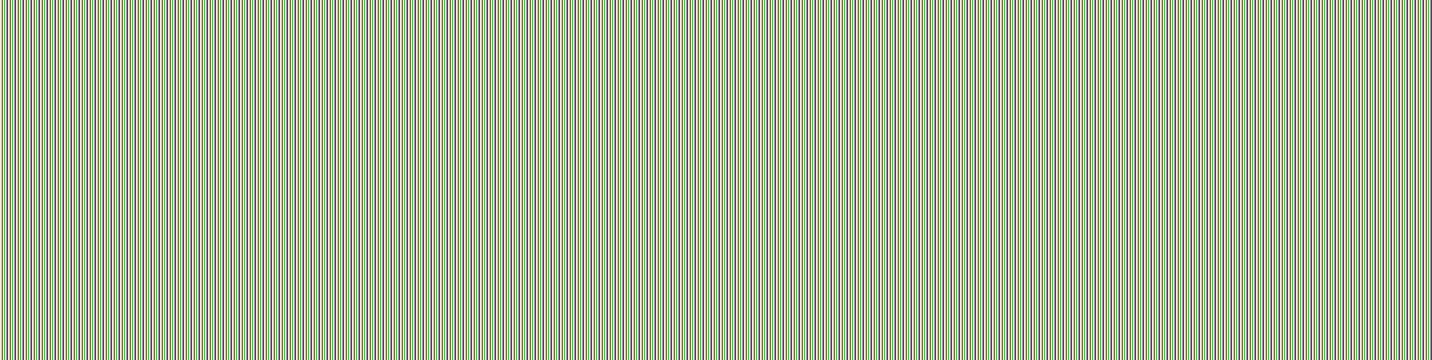

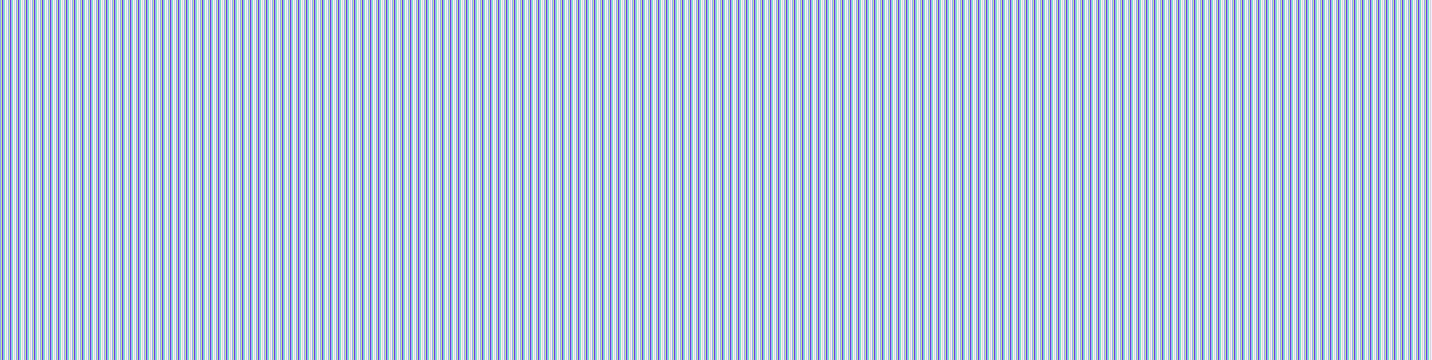

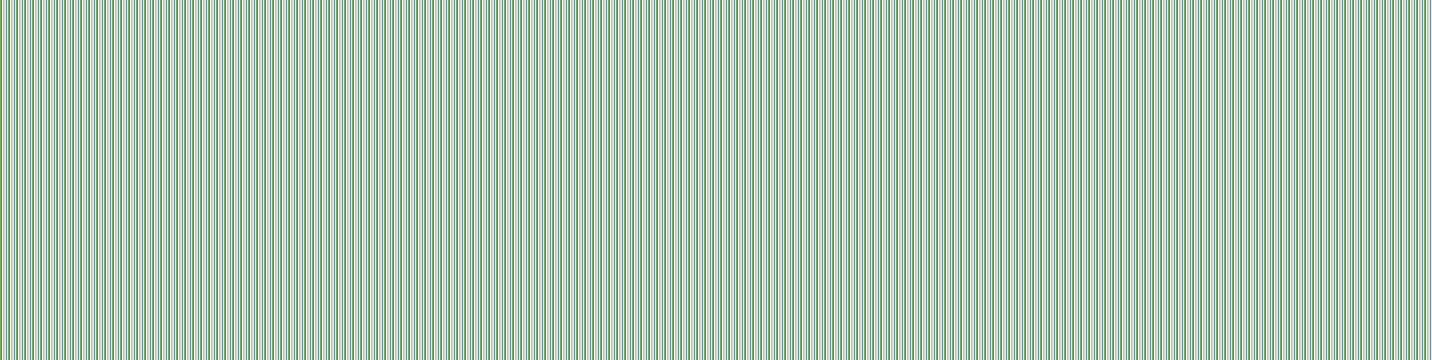

In [6]:
# Group by category and get the top 15 by volume
true_category_volume = events_cleaned.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(15)

# Plotting the adjusted data
fig_category_vol = px.bar(
    x=true_category_volume.values, 
    y=true_category_volume.index, 
    orientation='h',
    title='Total Trading Volume by Category (Using Event Tags)',
    labels={'x': 'Total Trading Volume (USD)', 'y': 'Category'},
    color=true_category_volume.values,
    color_continuous_scale='Magma'
)
fig_category_vol.update_layout(yaxis={'categoryorder':'total ascending'}, xaxis=dict(tickprefix="$"))
fig_category_vol.show()

# Print the real percentages
# print("Top 15 Categories by % of Total Platform Volume:\n")
# percentages = (true_category_volume / total_volume * 100)
# for cat, pct in percentages.items():
#     print(f"{cat}: {pct:.2f}%")



# Bubble Chart: Compare Number of Events vs Total Volume
cat_stats = events_cleaned.groupby('primary_category').agg(
    event_count=('id', 'count'),
    total_volume=('volume', 'sum')
).reset_index()

# Keep top 20 categories by volume to keep the chart clean
cat_stats_top = cat_stats.sort_values(by='total_volume', ascending=False).head(20)

fig_scatter = px.scatter(
    cat_stats_top,
    x='event_count',
    y='total_volume',
    size='total_volume',
    color='primary_category',
    hover_name='primary_category',
    title='Quantity vs. Volume: Is Sports Driven by High Frequency?',
    labels={
        'event_count': 'Total Number of Individual Events', 
        'total_volume': 'Cumulative Trading Volume ($)'
    },
    template='plotly_white',
    size_max=60,
    color_discrete_sequence=px.colors.qualitative.Prism
)
fig_scatter.update_layout(yaxis=dict(tickprefix="$"))
fig_scatter.show()

# Box Plot: Distribution of Volume Per-Event (Log Scale)
total_volume = events_cleaned.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(15)
top_5_cats = total_volume.head(5).index.tolist()
top_events_df = events_cleaned[events_cleaned['primary_category'].isin(top_5_cats)].copy()
top_events_df['log10_volume'] = np.log10(top_events_df['volume'] + 1)

fig_box = px.box(
    top_events_df, 
    x='primary_category', 
    y='log10_volume',
    color='primary_category',
    title='Market Volume Distribution per Category (Log10 Scale)',
    labels={
        'primary_category': 'Market Category', 
        'log10_volume': 'Log10(Volume per Event)'
    },
    template='plotly_white'
)
fig_box.update_layout(
    showlegend=False,
    yaxis=dict(
        tickvals=[0, 2, 4, 6, 8],
        ticktext=['$1', '$100', '$10,000', '$1M', '$100M']
    )
)
fig_box.show()

### Hypothesis 3: Anomalously large volume Bets (Identifying Manipulation)

Because we don't have access to individual wallets to see explicit "insider" trades, another way to test for manipulation is to look at **Anomalies in Volume**.

If a category typically sees $5,000 in median volume, but suddenly a single event in that category has $500,000+ in volume, it indicates someone potentially had inside knowledge and put huge money into an otherwise ignored niche market.

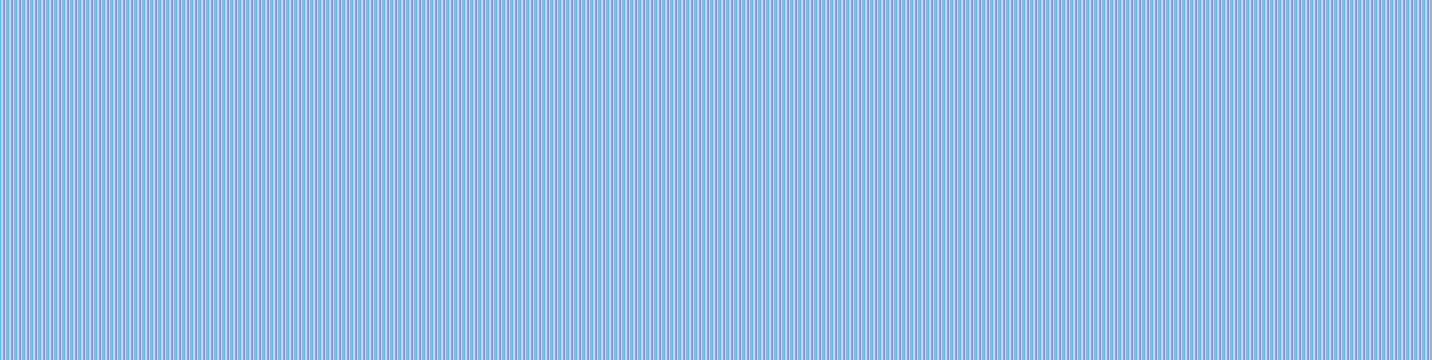

,title,primary_category,volume,median_volume
358,Chile Presidential Election,Elections,7.996871e+07,3163.062895
2249,New Jersey Governor Election Mikie Sherrill m...,Elections,6.168416e+06,3163.062895
25353,Raptors vs. Pacers,Basketball,2.968266e+06,1530.505050
538,Next Prime Minister of the Czech Republic,Elections,2.921806e+06,3163.062895
27611,Magic vs. Knicks,Basketball,2.853334e+06,1530.505050
18964,Heat vs. 76ers,Basketball,2.217809e+06,1530.505050
591,Which boroughs will Mamdani win in NYC Mayoral...,Elections,1.521563e+06,3163.062895
18965,Hornets vs. Hawks,Basketball,1.504032e+06,1530.505050
224,Gemini 3.0 Flash released by December 31?,Gemini 3,1.398055e+06,957.791039
415,Will Mikie Sherrill win by >14%?,Elections,1.275023e+06,3163.062895


In [8]:
import plotly.express as px

# Calculate median volume per category
category_medians = events_cleaned.groupby('primary_category')['volume'].median().reset_index()
category_medians.rename(columns={'volume': 'median_volume'}, inplace=True)
events_with_medians = events_cleaned.merge(category_medians, on='primary_category')

# Define anomalies based on hypothesis criteria (median <= $5k and volume >= $500k)
events_with_medians['is_anomaly'] = (
    (events_with_medians['median_volume'] <= 5000) & 
    (events_with_medians['volume'] >= 500000)
)
anomalies = events_with_medians[events_with_medians['is_anomaly']]

# Scatter Plot: Volume Anomalies in Niche Categories
fig_anom = px.scatter(
    events_with_medians[events_with_medians['median_volume'] < 50000], 
    x='median_volume', 
    y='volume', 
    color='is_anomaly',
    hover_name='title',
    hover_data=['primary_category', 'volume'],
    log_y=True,
    color_discrete_map={True: 'red', False: 'lightgray'},
    title='Volume Anomalies in Niche Categories',
    labels={'median_volume': 'Median Category Volume ($)', 'volume': 'Event Volume ($) [Log]'}
)
fig_anom.update_layout(template='plotly_white')
fig_anom.show()

# Display the detected anomalies
display(anomalies[['title', 'primary_category', 'volume', 'median_volume']].sort_values('volume', ascending=False).head(10))

## Reflection

**What is the hardest part of the project that you’ve encountered so far?**
From a data standpoint, our dataset (297,373 events and 88 columns from the scraped database; 43,840 events and 100,795 markets from Kaggle) has many columns which are entirely null or consist of a majority of missing values. Finding which columns were usable, identifying boolean columns for sorting versus actionable data columns, was very challenging. Since boolean columns were stored as integers and volume data was duplicated across multiple fields, cleaning, fixing, and aligning this data correctly took notable effort.

**What are your initial insights?**
Initial insights show that trading volume is heavily right-skewed: the mean volume (~$312K) heavily dwarfs the median volume (~$17.5K) on Polymarket. Most markets from the dataset essentially have little to no real trading, with the bottommost showing $0 in liquidity. Furthermore, niche category anomalies are very evident in the data, with isolated events (e.g., the Chile Presidential Election at ~$80M in volume) vastly outperforming their standard category medians.

**Are there any concrete results you can show at this point?**
Yes, concrete results can be seen in the form of our hypothesis testing and visualizations. For example, testing Hypothesis 2 confirmed that "Sports" is the largest traded platform category at ~33% overall volume (with the next closest market being ~7%). Similarly, in testing Hypothesis 3, anomalously large bets and the specific niche markets they are placed in are now clearly identifiable visually.

**Going forward, what are the current biggest problems you’re facing?**
Our current biggest problems are that our scraped datasets and Kaggle datasets have not yet been combined or cross-validated. Category-based columns also represent a small proportion compared to the total number of primary columns, and multiple of our initial hypotheses have not yet been completely explored.

**Do you think you are on track with your project? If not, what parts do you need to dedicate more time to?**
Yes, we are on track with the project. The parts that require more dedicated time are: the cross-validation and joining of our datasets, formulating additional hypotheses based on our EDA, adding more comprehensive visualizations and graphs, and exploring our current and new hypotheses completely to provide finalized analytical results.

**Given your initial exploration of the data, is it worth proceeding with your project, why?**
Yes, it is definitively worth proceeding. The project is already providing real results directly from the data and uncovering multiple meaningful insights. Moving forward, the data allows us to rigorously verify several other interesting hypotheses relating to the efficiency and behaviors of prediction markets.

## Next Steps
In the next month, our action items include:
1. Running a formalized logistic regression on resolved markets using `lastTradePrice`, `liquidity`, and `volume` as features to predict the final resolution outcome. We will report both accuracy and Brier scores, satisfying one ML requirement while formally testing Hypothesis 1. (**THIS WE NEED TO DO IN THE CURRENT SUBMISSION**)
2. Applying k-means clustering on market behavioral features (e.g., `volume`, `liquidity`, `duration`, `final price`) to identify natural "market archetypes". We will then compare prediction accuracy across these clusters, satisfying the second ML requirement.



## Generative AI Suggestions
*need to add later*